# Foreign holdings and currency on real data: what the tax man takes from US stocks, 1990-2022

A Canadian who owns US stocks pays two taxes a Canadian stock never charges. The first is withholding: the US keeps 15% of every US dividend before the investor sees it, and what happens to that 15% depends on the account (taxable, TFSA, RRSP) and on the wrapper (the US stocks themselves, a US-listed ETF, or a Canadian-listed ETF that holds US stocks). The second is currency: the CRA taxes the gain in Canadian dollars, and the cost base is fixed in Canadian dollars on the day of purchase, so a US stock that gained in US dollars can be a loss for tax purposes, and the reverse.

This notebook measures both on real history: the point-in-time S&P 500 panel from 1990 to 2022 (about 1,250 names that were ever in the index, delisted ones included, with each stock's real cash dividends) and the real daily USDCAD rate. **Data licence: the panel is an unlicensed mixed-source dataset (CRSP-derived until 2006, then Yahoo, Tiingo and Quandl WIKI) that you download yourself with `make data-panel` into the git-ignored folder `screenlab/data/panel/`. It is for local use, is not redistributed with this repository, and neither are results files that embed it.** The notebook cannot run without those files (the test skips when they are absent).

**Every chart and table carries one base case: buy and hold of the S&P 500 total-return index (`SP500_TR`) in the same account**, drawn grey and dashed and named in every legend, or the row marked "Buy and hold the index" in every table. The one exception is Section 4, where the question is about the currency itself: there the base case is the same trades taxed in US dollars (the currency ignored), with buy and hold of the index shown beside it. All taxes use the Canadian model for Alberta with other income of \$90,000 a year, the 2025 tax tables applied to every year from 1990 to 2022, an RRSP balance taxed at 30% at the end, and starting money of \$100,000. Not tax advice. The notebook runs in about a minute with the panel cache in place and writes no files.

In [1]:
import sys, time, warnings
from pathlib import Path
from dataclasses import replace
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display, Markdown

try:
    import screenlab
except ImportError:                       # running from a git checkout without installing the package
    sys.path.insert(0, str(Path.cwd().parent.parent))
    import screenlab
from screenlab import Lab
from screenlab.taxes import CanadianTax, TaxConfig, FX_WARNING
from screenlab.ops.account_compare import treatment, _ledger_capture, _withholding, _gross_direct_withholding
from screenlab.research import tax_plots as tp
from screenlab.research.montecarlo_sp500 import _style

%matplotlib inline
plt.rcParams["figure.dpi"] = 80
_style()
T_START = time.time()

START, END = "1990-01-01", "2022-12-30"
CAP = 100_000.0                                         # starting money, dollars
ACCOUNTS = ["taxable", "tfsa", "rrsp"]
ACC_NAME = {"taxable": "Taxable", "tfsa": "TFSA", "rrsp": "RRSP"}
GREY = tp.INDEX_COL                                     # the base case is always grey and dashed
WH_COL = {"lost": "#E69F00", "credited": "#56B4E9", "exempt": "#009E73"}
WH_NAME = {"lost": "Lost (nothing gives it back)", "credited": "Credited back (foreign tax credit)", "exempt": "Exempt (never withheld, treaty)"}
INDEX = "SP500_TR"

def say(text):                                          # a paragraph written from the run's own numbers, so it cannot drift from them
    display(Markdown(text))

def usd(v):                                             # dollars, with the dollar sign escaped so markdown does not read it as maths
    return f"-\\${-v:,.0f}" if v < -0.5 else f"\\${abs(v):,.0f}"

def pts(v):                                             # a fraction as points of growth a year
    return f"{100 * v:.2f}"

def spts(v):                                            # the same with its sign, for a difference
    return f"{100 * v:+.2f}"

# ---- the data: the point-in-time S&P 500 panel, 1990-2022 (EXACTLY these arguments, so the on-disk cache is hit)
lab = Lab.real_sp500(start="1990-01-01", end="2022-12-30")
card = lab.data_card()
fx = lab.macro.get("fx").dropna()
fx = fx[(fx.index >= START) & (fx.index <= END)]
YEARS = (pd.Timestamp(END) - pd.Timestamp(START)).days / 365.25

# ---- the tax setting: Alberta, other income $90,000, 2025 tables for every year, RRSP balance taxed at 30% at the end
MODEL = CanadianTax("AB", other_income=90_000)
TC = TaxConfig(model=MODEL, macro=lab.macro, rrsp_withdrawal_rate=0.30, capital=CAP, index_foreign_share=1.0)

def run(lab_, screens, account, **kw):
    # Backtest `screens` and the index in `account`, keeping the tax stage's event ledger on every tax table.
    with _ledger_capture():
        return lab_.backtest(screens, tax=replace(TC, account=account, **kw), start=START, end=END)

def ledger_dollars(tab, account):
    # The foreign withholding of one run, by year and by what happened to it, in dollars (start money $100,000).
    curve, ev = tab.attrs["ledger"]
    ev = ev.reindex(columns=["div_fx", "wh_fx", "wh_fund", "wh_lost"]).fillna(0.0)
    y = ev.groupby(ev.index.year).sum()
    f = (tab["wealth_after_tax"] / tab["wealth_pre_tax"]).shift(1).fillna(1.0)      # share of the account left after the tax paid so far
    y = y.mul(CAP * f.reindex(y.index).to_numpy(), axis=0)
    out = pd.DataFrame(index=y.index, dtype=float)
    out["lost"] = y["wh_fund"] + y["wh_lost"] + (y["wh_fx"] if account == "tfsa" else 0.0)
    out["credited"] = y["wh_fx"] if account == "taxable" else 0.0
    out["exempt"] = y["div_fx"] * TC.rate_for("US") if account == "rrsp" else 0.0
    return out

def cad_cagr(curve):
    # Growth a year in Canadian dollars of a USD total-return curve held with no currency hedge.
    c = curve.dropna()
    f = fx.reindex(c.index, method="ffill").bfill()
    return (c.iloc[-1] / c.iloc[0] * f.iloc[-1] / f.iloc[0]) ** (365.25 / (c.index[-1] - c.index[0]).days) - 1

SCREENS = ["dogs", "momentum_12m"]
# ---- Section 2: the US stocks held directly (the library's default for a US name), three accounts
REP = {a: run(lab, SCREENS, a) for a in ACCOUNTS}

# ---- Section 3: the same holdings as a Canadian-listed ETF on US stocks. A model, not a fund: the dataset's security_meta is
# overridden on a copy (wrapper etf_ca, underlying_domicile US), so the 15% is taken inside the fund in every account. The ETF's
# NAV stays in US dollars (currency USD), so the CAD-basis gain is identical and ONLY the withholding treatment differs.
meta = lab.market.dataset.security_meta.copy()
meta["wrapper"], meta["domicile"], meta["listing"], meta["underlying_domicile"], meta["currency"] = "etf_ca", "CA", "CA", "US", "USD"
import dataclasses
lab_etf = Lab.from_dataset(dataclasses.replace(lab.market.dataset, security_meta=meta), screens=lab.screens, macro=lab.macro)
REP_ETF = {a: run(lab_etf, ["dogs"], a) for a in ACCOUNTS}

# ---- the table of Section 2 and 3: one row per (holding, wrapper, account)
def wh_row(rep, label, account, wrapper, gross):
    tab = rep.tax[label]
    pt = _withholding(tab, account, TC.rate_for("US"), gross)
    d = ledger_dollars(tab, account)
    r = rep.table.loc[label]
    return dict(holding=label, wrapper=wrapper, account=account, CAGR=r["CAGR"], AfterTaxCAGR=r["AfterTaxCAGR"],
                lost_pts=pt["WHLost/yr"], credited_pts=pt["WHCredited/yr"], exempt_pts=pt["WHExempt/yr"],
                lost=d["lost"].sum(), credited=d["credited"].sum(), exempt=d["exempt"].sum())

rows = []
for label in [INDEX, *SCREENS]:
    gross = _gross_direct_withholding(REP["taxable"].tax[label])
    for a in ACCOUNTS:
        rows.append(wh_row(REP[a], label, a, "US stocks held directly", gross))
for a in ACCOUNTS:
    rows.append(wh_row(REP_ETF[a], "dogs", a, "Canadian-listed ETF (model)", None))
W = pd.DataFrame(rows).set_index(["holding", "wrapper", "account"])
DIRECT, ETF = "US stocks held directly", "Canadian-listed ETF (model)"
W["vs_base"] = [W.loc[(h, w, a), "AfterTaxCAGR"] - W.loc[(INDEX, DIRECT, a), "AfterTaxCAGR"] for h, w, a in W.index]

# ---- Section 4: the currency. The same trades taxed on the Canadian-dollar basis (the USDCAD series) and, as the base,
# with the currency ignored (macro=None: gains and dividends taxed in US dollars, which the library warns about). Taxes are paid
# from outside the account here (pay_from_portfolio=False) so both runs hold exactly the same dollars and differ only in the basis.
NOPAY = dict(pay_from_portfolio=False)
REP_CAD = run(lab, SCREENS, "taxable", **NOPAY)
REP_USD = run(lab, SCREENS, "taxable", macro=None, **NOPAY)
TAX_NOTE = [w for w in REP["taxable"].tax["dogs"].attrs["warnings"] if "no tax table" in w][0]
FX_NOTE = REP_USD.tax["dogs"].attrs["warnings"][0]
REP_SELL = run(lab, SCREENS, "taxable", liquidate_at_end=True, **NOPAY)               # sold on the last day: the whole gain realized
REP_SELL_USD = run(lab, SCREENS, "taxable", macro=None, liquidate_at_end=True, **NOPAY)
print(f"setup and runs: {time.time() - T_START:.0f} s")

setup and runs: 39 s


In [2]:
# ---- derived numbers for sections 1 to 5 (hidden with the setup: the sections below only draw and write)
LABELS = [INDEX, *SCREENS]

def basis_table(label):
    # Realized gains and tax by year on the Canadian-dollar basis and, as the base, with the currency ignored.
    c, u = REP_CAD.tax[label], REP_USD.tax[label]
    g = pd.DataFrame({"net_cad": c["realized_gains"] + c["realized_losses"], "net_usd": u["realized_gains"] + u["realized_losses"],
                      "gain_tax_cad": c["tax_capital_gains"], "gain_tax_usd": u["tax_capital_gains"],
                      "tax_cad": c["tax_paid"], "tax_usd": u["tax_paid"]})
    g["flip"] = g["net_cad"].round(0) * g["net_usd"].round(0) < 0
    return g

G = {l: basis_table(l) for l in SCREENS}
SELL = {l: dict(cad=REP_SELL.tax[l]["tax_paid"].sum(), usd=REP_SELL_USD.tax[l]["tax_paid"].sum(),
                gain_cad=REP_SELL.tax[l]["realized_gains"].iloc[-1], gain_usd=REP_SELL_USD.tax[l]["realized_gains"].iloc[-1]) for l in SCREENS}
FX0, FX1 = float(fx.iloc[0]), float(fx.iloc[-1])

# The library taxes the passive index in US dollars (it has no per-name trades to convert). Its Canadian-dollar cost base is rebuilt
# here from the library's own dividend stream: each reinvested dividend adds to the cost base at the USDCAD of its payment date.
from screenlab.taxes import index_yield
_b = lab.passive()
_c = (REP_CAD.curves[INDEX] / REP_CAD.curves[INDEX].iloc[0]).astype(float)
_y, _ = index_yield(_b, lab.market, TC, START)
_ys = pd.Series(_y, dtype=float).sort_index() if not np.isscalar(_y) else None
_yy = _ys.reindex(_ys.index.union(_c.index.year.unique())).ffill().bfill().loc[_c.index.year[:-1]].to_numpy() if _ys is not None else _y
_div = _c.to_numpy()[:-1] * _yy * np.diff(((_c.index - _c.index[0]).days / 365.25).to_numpy())
_fxb = (fx.reindex(_c.index, method="ffill").bfill() / FX0).to_numpy()
IDX_USD_GAIN = CAP * (float(_c.iloc[-1]) - 1.0 - _div.sum())
IDX_CAD_GAIN = CAP * (float(_c.iloc[-1]) * _fxb[-1] - 1.0 - (_div * _fxb[1:]).sum())
_lib = float(REP_SELL_USD.tax[INDEX]["realized_gains"].iloc[-1])
assert abs(IDX_USD_GAIN / _lib - 1) < 0.002, (IDX_USD_GAIN, _lib)                  # the rebuild reproduces the library's own US-dollar gain
def sale_tax(gain):                                        # tax on a one-off gain realized in the last year, Alberta, other income $90,000
    return float(MODEL.assess_year(2022, capital_gains_net=gain, account="taxable").total)
IDX_USD_TAX, IDX_CAD_TAX = sale_tax(IDX_USD_GAIN), sale_tax(IDX_CAD_GAIN)

CUR = {}                                                  # per holding: growth a year in USD and in CAD, gains, tax, flips
for l in LABELS:
    row = dict(usd_cagr=REP["taxable"].table.loc[l, "CAGR"], cad_cagr=cad_cagr(REP["taxable"].curves[l]))
    if l in G:
        g = G[l]
        row.update(net_cad=g["net_cad"].sum(), net_usd=g["net_usd"].sum(), flips=int(g["flip"].sum()), flip_years=list(g.index[g["flip"]]),
                   tax_cad=g["tax_cad"].sum(), tax_usd=g["tax_usd"].sum(), gtax_cad=g["gain_tax_cad"].sum(), gtax_usd=g["gain_tax_usd"].sum(),
                   sell_cad=SELL[l]["cad"], sell_usd=SELL[l]["usd"], gain_cad=SELL[l]["gain_cad"], gain_usd=SELL[l]["gain_usd"])
    else:
        row.update(gain_cad=IDX_CAD_GAIN, gain_usd=IDX_USD_GAIN, sell_cad=np.nan, sell_usd=np.nan)
    CUR[l] = row
PERIODS = [("1990-2001", 1990, 2001, "US dollar climbs"), ("2002-2007", 2002, 2007, "US dollar falls"),
           ("2008-2012", 2008, 2012, "swings around parity"), ("2013-2016", 2013, 2016, "US dollar climbs again"),
           ("2017-2022", 2017, 2022, "range-bound")]
ye = fx.groupby(fx.index.year).last()
def fx_change(a, b):                                       # USDCAD from the end of year a-1 (the first day for 1990) to the end of year b
    start = ye.loc[a - 1] if (a - 1) in ye.index else FX0
    return ye.loc[b] / start - 1
PER = pd.DataFrame([dict(period=p, what=w, usdcad_change=fx_change(a, b),
                         net_cad=G["dogs"].loc[a:b, "net_cad"].sum(), net_usd=G["dogs"].loc[a:b, "net_usd"].sum(),
                         flips=int(G["dogs"].loc[a:b, "flip"].sum()),
                         tax_cad=G["dogs"].loc[a:b, "tax_cad"].sum(), tax_usd=G["dogs"].loc[a:b, "tax_usd"].sum())
                    for p, a, b, w in PERIODS]).set_index("period")

In [3]:
def dg(a, c): return W.loc[("dogs", DIRECT, a), c]
def ix(a, c): return W.loc[(INDEX, DIRECT, a), c]
def et(a, c): return W.loc[("dogs", ETF, a), c]
def mo(a, c): return W.loc[("momentum_12m", DIRECT, a), c]
d_ = CUR["dogs"]
sell_tax_cad, sell_tax_usd = d_["sell_cad"] - d_["tax_cad"], d_["sell_usd"] - d_["tax_usd"]       # tax added by the final sale
say(f"""
## Summary

**What withholding costs.** The US kept 15% of every dividend. On {usd(CAP)} put into the dogs screen (the ten highest dividend yields of the S&P 500) in 1990 and left to compound to 2022, held as the US stocks themselves, it cost nothing in a taxable account (the foreign tax credit gave back {usd(dg("taxable", "credited"))}), {usd(dg("tfsa", "lost"))} for good in a TFSA ({pts(dg("tfsa", "lost_pts"))} points of growth a year), and nothing in an RRSP, where the treaty exempted {usd(dg("rrsp", "exempt"))}. Held through a Canadian-listed ETF on the same stocks it cost {usd(et("taxable", "lost"))} in a taxable account, {usd(et("tfsa", "lost"))} in a TFSA and {usd(et("rrsp", "lost"))} in an RRSP, {pts(et("taxable", "lost_pts"))} points a year in every account, because the fund pays the 15% before the account sees it; that left {pts(dg("taxable", "AfterTaxCAGR") - et("taxable", "AfterTaxCAGR"))} points a year less after-tax growth than the stocks held directly in a taxable account and {pts(dg("rrsp", "AfterTaxCAGR") - et("rrsp", "AfterTaxCAGR"))} less in an RRSP. Against the base case, buy and hold of the index in the same account, which has a low yield and so lost {usd(ix("tfsa", "lost"))} in a TFSA ({pts(ix("tfsa", "lost_pts"))} points a year) and was credited {usd(ix("taxable", "credited"))} in a taxable account, the dogs' after-tax growth minus the index's was {spts(dg("taxable", "vs_base"))} points a year in a taxable account ({pts(dg("taxable", "AfterTaxCAGR"))}% against {pts(ix("taxable", "AfterTaxCAGR"))}%), {spts(dg("tfsa", "vs_base"))} in a TFSA and {spts(dg("rrsp", "vs_base"))} in an RRSP; withholding is a large cost only for the high-yield screen and only in a TFSA or inside a Canadian-listed fund.

**What the currency did.** USDCAD went from {FX0:.3f} on the first day of 1990 to {FX1:.3f} on the last day of 2022 ({FX1 / FX0 - 1:+.0%}), through a high of {fx.max():.3f} in {fx.idxmax():%B %Y} and a low of {fx.min():.3f} in {fx.idxmin():%B %Y}. Unhedged, the base case, the index, grew {pts(CUR[INDEX]["cad_cagr"])}% a year in Canadian dollars against {pts(CUR[INDEX]["usd_cagr"])}% in US dollars, and the dogs {pts(d_["cad_cagr"])}% against {pts(d_["usd_cagr"])}%. The trades of the dogs realized a net {usd(d_["net_cad"])} over the 33 years on the Canadian-dollar basis the CRA uses, against {usd(d_["net_usd"])} with the currency ignored, and the net gain changed sign in {d_["flips"]} of the 33 years ({", ".join(str(y) for y in d_["flip_years"])}). Selling everything on the last day, the 33 years cost {usd(d_["sell_cad"])} of tax on the Canadian-dollar basis against {usd(d_["sell_usd"])} in US dollars, {usd(d_["sell_cad"] - d_["sell_usd"])} more ({d_["sell_cad"] / d_["sell_usd"] - 1:+.1%}), of which {usd(sell_tax_cad - sell_tax_usd)} came from the final sale. For the base case, the index sold on the last day, the taxable gain was {usd(IDX_CAD_GAIN)} in Canadian dollars against {usd(IDX_USD_GAIN)} in US dollars, and the tax {usd(IDX_CAD_TAX - IDX_USD_TAX)} higher.
""")


## Summary

**What withholding costs.** The US kept 15% of every dividend. On \$100,000 put into the dogs screen (the ten highest dividend yields of the S&P 500) in 1990 and left to compound to 2022, held as the US stocks themselves, it cost nothing in a taxable account (the foreign tax credit gave back \$320,426), \$583,003 for good in a TFSA (1.51 points of growth a year), and nothing in an RRSP, where the treaty exempted \$837,075. Held through a Canadian-listed ETF on the same stocks it cost \$260,011 in a taxable account, \$583,003 in a TFSA and \$583,003 in an RRSP, 1.51 points a year in every account, because the fund pays the 15% before the account sees it; that left 1.04 points a year less after-tax growth than the stocks held directly in a taxable account and 1.74 less in an RRSP. Against the base case, buy and hold of the index in the same account, which has a low yield and so lost \$57,233 in a TFSA (0.28 points a year) and was credited \$53,389 in a taxable account, the dogs' after-tax growth minus the index's was -0.28 points a year in a taxable account (8.66% against 8.95%), +2.20 in a TFSA and +3.60 in an RRSP; withholding is a large cost only for the high-yield screen and only in a TFSA or inside a Canadian-listed fund.

**What the currency did.** USDCAD went from 1.161 on the first day of 1990 to 1.353 on the last day of 2022 (+17%), through a high of 1.613 in January 2002 and a low of 0.917 in November 2007. Unhedged, the base case, the index, grew 10.11% a year in Canadian dollars against 9.59% in US dollars, and the dogs 13.76% against 13.24%. The trades of the dogs realized a net \$165,655 over the 33 years on the Canadian-dollar basis the CRA uses, against -\$149,817 with the currency ignored, and the net gain changed sign in 3 of the 33 years (1993, 2006, 2019). Selling everything on the last day, the 33 years cost \$2,562,663 of tax on the Canadian-dollar basis against \$2,315,519 in US dollars, \$247,144 more (+10.7%), of which \$154,046 came from the final sale. For the base case, the index sold on the last day, the taxable gain was \$1,854,844 in Canadian dollars against \$1,546,005 in US dollars, and the tax \$74,121 higher.


## 1. The data: what stands behind every number

The question is what the panel actually holds and what the exchange rate did over its 33 years, so that every later figure can be read against it. This section comes first because Sections 2 to 5 use nothing but the series shown here.

The panel gives each stock's close, a total-return price that includes dividends, its cash dividend on each ex-date and the dates it was a member of the S&P 500, so on any date the universe is the index as it was then, with delisted names included. The exchange rate is the Federal Reserve's H.10 daily USDCAD (Canadian dollars per US dollar). **The base case is buy and hold of the S&P 500 total-return index (`SP500_TR`), the real daily index with Shiller's dividend yield added back**, shown in US dollars (grey, dashed) and in Canadian dollars in Figure 1 and as the first row of Table 1.

In [4]:
print(card.line())
for w in card.warnings():
    print(w)
print("tax tables:", TAX_NOTE)

Data: sp500_panel, 1990-01-02..2022-12-30, 1248 names, benchmark SP500_TR (total_return), PIT yes, delisted yes (631), survivorship -0.7%/yr
foreign: 100% of names (US 100%), currencies USD; withholding: taxable creditable (FTC), tfsa lost, rrsp exempt (US-listed); Canadian ETF on foreign stocks: lost in every account
NOTE: a name that leaves the index but keeps trading leaves the universe at the next rebalance and can still be sold at its price; a name whose prices end (delisted, merged) takes the library's delisting haircut (Config.delist_return, default -30%), which is harsh for acquisitions paid at a premium.
NOTE: source mix by era: 1990-1994: crsp 96%, other 4%; 1995-1999: yahoo 44%, crsp 40%, tiingo 11%, other 5%; 2000-2004: yahoo 53%, crsp 27%, tiingo 14%, other 6%; 2005-2009: yahoo 61%, tiingo 17%, crsp 15%, other 7%; 2010-2014: yahoo 70%, tiingo 19%, other 7%, crsp 4%; 2015-2019: yahoo 80%, tiingo 15%, other 3%; 2020-2024: yahoo 90%, tiingo 9%.
NOTE: benchmark SP500_EW_PIT is

In [5]:
px, uni, f = lab.market.prices, lab.market.universe, lab.market.fund
ts10 = pd.Timestamp("2010-06-30")
snap10 = lab.market.view(lab.market.trading_day(ts10)).reindex(uni.members(ts10))          # the index as it was on 2010-06-30
pay10, yld10 = (snap10["dividend"] > 0).mean(), snap10.loc[snap10["dividend"] > 0, "div_yield"].median()
rows = [("Names priced (ever in the S&P 500 between 1990 and 2022)", f"{px.shape[1]:,}"),
        ("Delisted names among them (prices end before 2022)", f"{card.n_delisted:,}"),
        ("Members of the index on 1990-06-29 / 2000-06-30 / 2010-06-30 / 2022-06-30",
         " / ".join(str(len(uni.members(pd.Timestamp(d)))) for d in ("1990-06-29", "2000-06-30", "2010-06-30", "2022-06-30"))),
        ("Share of the members on 2010-06-30 that paid a dividend in the previous year, median yield of the payers", f"{pay10:.0%}, {yld10:.2%}"),
        ("Highest trailing yield kept in the data (distress names are kept)", f"{f['div_yield'].max():.0%}"),
        ("USDCAD on the first / last day", f"{FX0:.4f} / {FX1:.4f}"),
        ("USDCAD high / low", f"{fx.max():.4f} on {fx.idxmax():%Y-%m-%d} / {fx.min():.4f} on {fx.idxmin():%Y-%m-%d}"),
        ("Buy and hold the index (SP500_TR), growth a year, 1990-2022: US dollars / Canadian dollars",
         f"{CUR[INDEX]['usd_cagr']:.2%} / {CUR[INDEX]['cad_cagr']:.2%}")]
t1 = pd.DataFrame(rows, columns=["What", "Value"]).set_index("What")
print("Table 1. What the panel and the exchange rate hold; the last row is the base case, buy and hold of the index")
t1

Table 1. What the panel and the exchange rate hold; the last row is the base case, buy and hold of the index


,Value
What,
Names priced (ever in the S&P 500 between 1990 and 2022),"1,248"
Delisted names among them (prices end before 2022),631
Members of the index on 1990-06-29 / 2000-06-30 / 2010-06-30 / 2022-06-30,500 / 500 / 500 / 503
"Share of the members on 2010-06-30 that paid a dividend in the previous year, median yield of the payers","74%, 2.11%"
Highest trailing yield kept in the data (distress names are kept),229%
USDCAD on the first / last day,1.1605 / 1.3532
USDCAD high / low,1.6128 on 2002-01-18 / 0.9168 on 2007-11-07
"Buy and hold the index (SP500_TR), growth a year, 1990-2022: US dollars / Canadian dollars",9.59% / 10.11%


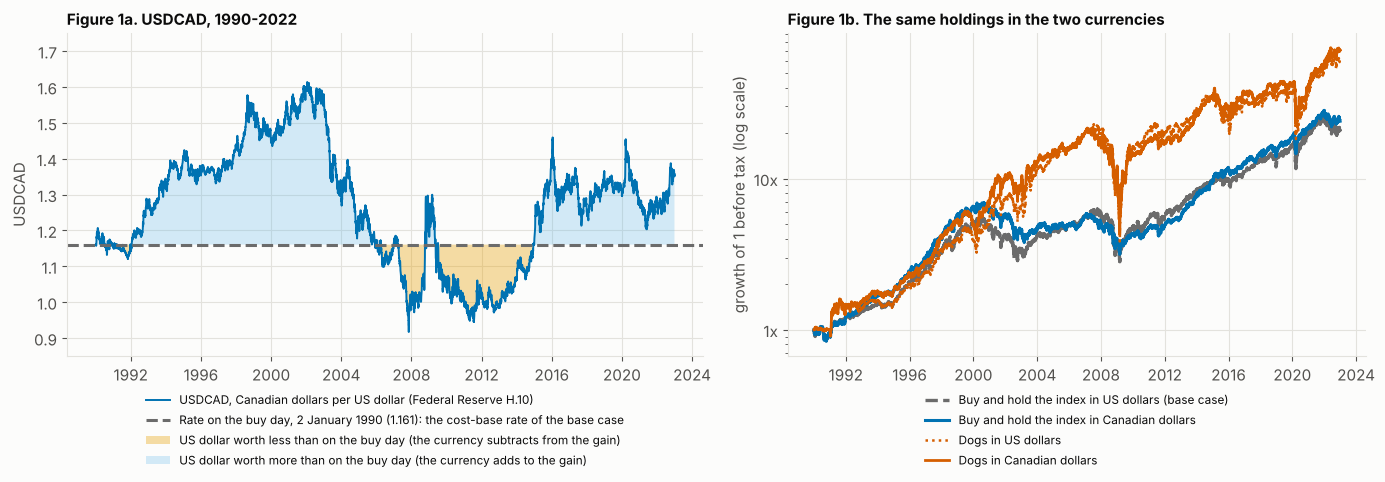

In [6]:
cum = lambda c: (c / c.iloc[0])
fxd = fx.reindex(REP["taxable"].curves.index, method="ffill").bfill()
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw=dict(width_ratios=[1.1, 1]))
ax = tp._ax(axes[0])
ax.plot(fx.index, fx.to_numpy(), color="#0072B2", lw=1.4, label="USDCAD, Canadian dollars per US dollar (Federal Reserve H.10)")
ax.axhline(FX0, color=GREY, ls="--", lw=2.2, label=f"Rate on the buy day, 2 January 1990 ({FX0:.3f}): the cost-base rate of the base case")
ax.fill_between(fx.index, fx.to_numpy(), FX0, where=(fx.to_numpy() < FX0), color="#E69F00", alpha=0.35, lw=0,
                label="US dollar worth less than on the buy day (the currency subtracts from the gain)")
ax.fill_between(fx.index, fx.to_numpy(), FX0, where=(fx.to_numpy() >= FX0), color="#56B4E9", alpha=0.25, lw=0,
                label="US dollar worth more than on the buy day (the currency adds to the gain)")
ax.set_ylabel("USDCAD"); ax.set_ylim(0.85, 1.75)
ax.set_title("Figure 1a. USDCAD, 1990-2022", loc="left", fontsize=11, fontweight="bold")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), fontsize=8.5, frameon=False)
ax = tp._ax(axes[1])
base_usd = cum(REP["taxable"].curves[INDEX])
ax.plot(base_usd.index, base_usd.to_numpy(), color=GREY, ls="--", lw=2.4, label="Buy and hold the index in US dollars (base case)")
ax.plot(base_usd.index, (base_usd * fxd / FX0).to_numpy(), color="#0072B2", lw=2.2, label="Buy and hold the index in Canadian dollars")
dg_c = cum(REP["taxable"].curves["dogs"])
ax.plot(dg_c.index, dg_c.to_numpy(), color="#D55E00", ls=":", lw=1.8, label="Dogs in US dollars")
ax.plot(dg_c.index, (dg_c * fxd / FX0).to_numpy(), color="#D55E00", lw=2.0, label="Dogs in Canadian dollars")
ax.set_yscale("log"); ax.set_ylabel("growth of 1 before tax (log scale)")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:g}x")
ax.set_title("Figure 1b. The same holdings in the two currencies", loc="left", fontsize=11, fontweight="bold")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), fontsize=8.5, frameon=False)
fig.tight_layout(); plt.show()

In [7]:
say(f"""
### What the evidence says

The panel gives {px.shape[1]:,} priced names, {card.n_delisted:,} of them delisted, a universe of about {len(uni.members(pd.Timestamp("2010-06-30")))} members at any date and real dividends from {pay10:.0%} of the members on 2010-06-30, so the withholding and the cost base below are computed on dividends and trades that happened and not on an assumed yield. The exchange rate matters from the first day: against the base case, buy and hold of the index, the move of USDCAD from {FX0:.3f} to {FX1:.3f} added {pts(CUR[INDEX]["cad_cagr"] - CUR[INDEX]["usd_cagr"])} points a year, {pts(CUR[INDEX]["cad_cagr"])}% in Canadian dollars against {pts(CUR[INDEX]["usd_cagr"])}% in US dollars, before any tax. The rate spent the years between {fx.idxmax():%Y} and {fx.idxmin():%Y} falling by {1 - fx.min() / fx.max():.0%}, and the shaded area in Figure 1a shows how long the US dollar was worth less than on the buy day, which is when a US-dollar gain is shrunk or reversed on the CRA's Canadian-dollar books.
""")
assert CUR[INDEX]["cad_cagr"] > CUR[INDEX]["usd_cagr"]


### What the evidence says

The panel gives 1,248 priced names, 631 of them delisted, a universe of about 500 members at any date and real dividends from 74% of the members on 2010-06-30, so the withholding and the cost base below are computed on dividends and trades that happened and not on an assumed yield. The exchange rate matters from the first day: against the base case, buy and hold of the index, the move of USDCAD from 1.161 to 1.353 added 0.51 points a year, 10.11% in Canadian dollars against 9.59% in US dollars, before any tax. The rate spent the years between 2002 and 2007 falling by 43%, and the shaded area in Figure 1a shows how long the US dollar was worth less than on the buy day, which is when a US-dollar gain is shrunk or reversed on the CRA's Canadian-dollar books.


## 2. Withholding on real dividends: the 15% in each account

Section 1 showed the data; the question now is what the US withholding cost on those real dividends in each account, and who bears it. It follows from Section 1 because the dividends counted here are the panel's, taken stock by stock. Two holdings are compared: the **dogs** screen, the ten highest trailing dividend yields of the S&P 500, rebalanced each year (13.2% a year before tax, yields of 5% to 10% and more, so withholding matters most), and **the index**, which is the base case, a yield of about 2%. Each is held in a taxable account, a TFSA and an RRSP, as the US stocks themselves.

**The base case is buy and hold of the index in the same account.** In Table 2 each row is one holding in one account, and the index rows are marked as the base. The dollar columns are the sum over the 33 years of the withholding on \$100,000, started in 1990 and left to compound with the tax paid from the account, so late years weigh most; the points-a-year columns divide the same withholding by the average wealth and so compare across holdings. *Lost* is withholding nothing gives back (a TFSA, or a fund's own); *credited* is what the foreign tax credit returns in a taxable account; *exempt* is what the treaty never withholds in an RRSP.

In [8]:
t2 = W.reset_index()
t2 = t2[(t2["wrapper"] == DIRECT) & t2["holding"].isin([INDEX, "dogs"])].copy()
t2["row"] = np.where(t2["holding"] == INDEX, "Buy and hold the index (base)", "Dogs")
t2["account"] = t2["account"].map(ACC_NAME)
t2 = t2.set_index(["row", "account"])[["CAGR", "AfterTaxCAGR", "vs_base", "lost", "credited", "exempt", "lost_pts", "credited_pts", "exempt_pts"]]
t2.columns = ["Growth a year before tax", "Growth a year after tax", "After-tax growth minus the index in the same account",
              "Withholding lost ($)", "Credited back ($)", "Exempt ($)", "Lost (points a year)", "Credited (points a year)", "Exempt (points a year)"]
print("Table 2. Foreign withholding on real dividends, $100,000 started in 1990, by account; the index rows are the base case")
t2.style.format({c: "{:.2%}" for c in t2.columns[:3]} | {c: "{:,.0f}" for c in t2.columns[3:6]} | {c: "{:.2%}" for c in t2.columns[6:]})

Table 2. Foreign withholding on real dividends, $100,000 started in 1990, by account; the index rows are the base case


Figure 2 shows the same withholding year by year in dollars, one panel per account. The bars are the dogs, stacked by what happened to the withholding: amber is lost, blue is credited back by the foreign tax credit, green is exempt. The grey dashed line with diamonds is the base case, the withholding on buy and hold of the index in the same account (all three kinds added together). The bars grow over the years because the account does.

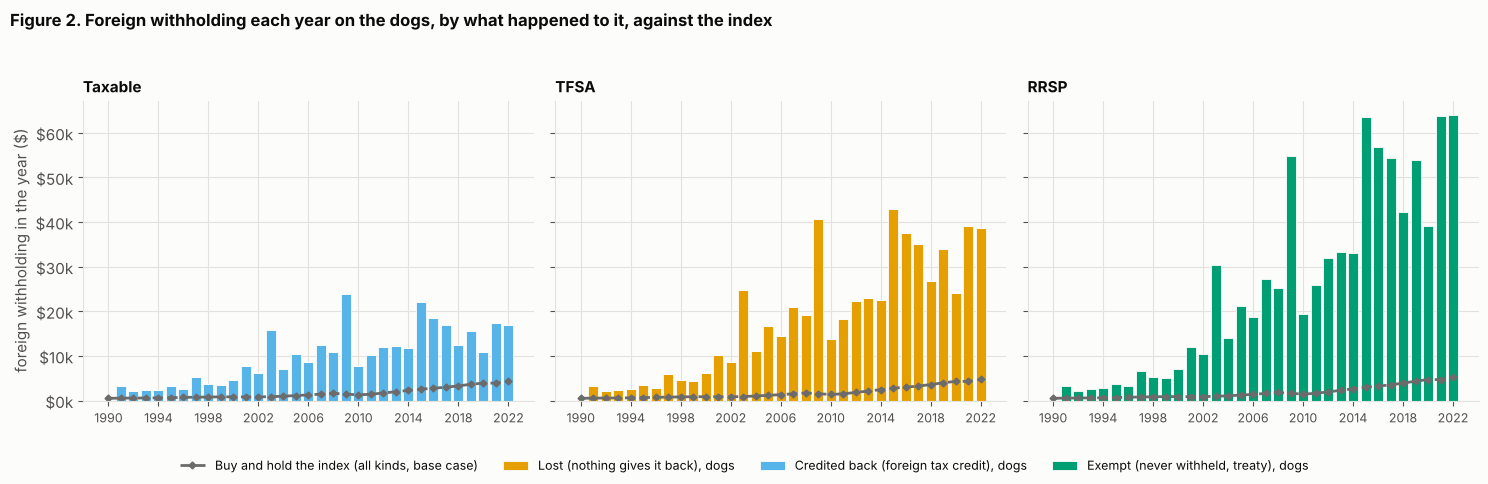

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
yrs = sorted(ledger_dollars(REP["taxable"].tax["dogs"], "taxable").index)
for ax, a in zip(axes, ACCOUNTS):
    ax = tp._ax(ax)
    d = ledger_dollars(REP[a].tax["dogs"], a).reindex(yrs).fillna(0.0)
    b = ledger_dollars(REP[a].tax[INDEX], a).reindex(yrs).fillna(0.0).sum(axis=1)
    bottom = np.zeros(len(yrs))
    for k in ("lost", "credited", "exempt"):
        ax.bar(range(len(yrs)), d[k].to_numpy(), 0.8, bottom=bottom, color=WH_COL[k], label=WH_NAME[k] + ", dogs", edgecolor=tp.SURFACE, lw=0.6)
        bottom += d[k].to_numpy()
    ax.plot(range(len(yrs)), b.to_numpy(), color=GREY, ls="--", lw=2.0, marker="D", ms=3.5, label="Buy and hold the index (all kinds, base case)")
    ax.set_xticks(range(0, len(yrs), 4), [str(y) for y in yrs[::4]], fontsize=9)
    ax.set_title(f"{ACC_NAME[a]}", loc="left", fontsize=11, fontweight="bold")
    ax.yaxis.set_major_formatter(lambda v, _: f"${v / 1e3:,.0f}k")
axes[0].set_ylabel("foreign withholding in the year ($)")
h, l = axes[0].get_legend_handles_labels()
for x in axes[1:]:
    h2, l2 = x.get_legend_handles_labels(); h += [i for i, n in zip(h2, l2) if n not in l]; l += [n for n in l2 if n not in l]
fig.legend(h, l, loc="lower center", ncol=4, fontsize=9, frameon=False)
fig.suptitle("Figure 2. Foreign withholding each year on the dogs, by what happened to it, against the index", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout(rect=(0, 0.08, 1, 0.95)); plt.show()

Figure 3 turns the withholding into the growth that is left. For each account the light bar is the dogs' growth a year before tax and the dark bar after all Canadian tax (dividends, gains and, for the RRSP, the 30% withdrawal tax), with the drag written above. The grey dashed mark across each group is the base case, what buy and hold of the index left in the same account. Where the dark bar passes the mark, the dogs beat the index after tax in that account.

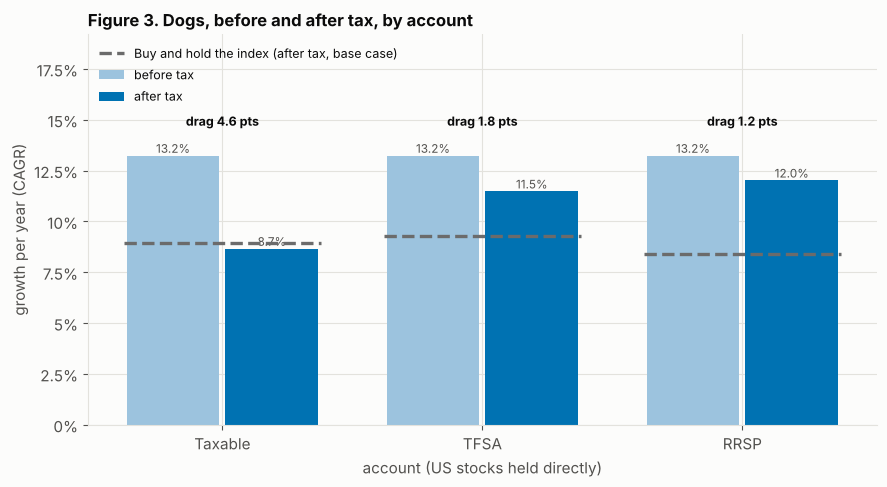

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
tab3 = pd.DataFrame([dict(label=ACC_NAME[a], CAGR=dg(a, "CAGR"), AfterTaxCAGR=dg(a, "AfterTaxCAGR")) for a in ACCOUNTS])
tp.tax_drag_bars(tab3, ax=ax, baseline=[ix(a, "AfterTaxCAGR") for a in ACCOUNTS], baseline_label="Buy and hold the index (after tax, base case)", legend=True,
                 title="Figure 3. Dogs, before and after tax, by account")
ax.set_xlabel("account (US stocks held directly)")
fig.tight_layout(); plt.show()

Figure 4 reads the rule back from the tax stage's own ledger: for each account, was the dogs' withholding lost, credited back or exempt? The cells are filled from the dollars in Table 2 and then checked against the matrix documented in `docs/TAXES.md`. The grey dashed frame marks the taxable account, where the base case, buy and hold of the index, is held in the comparison.

the ledger of the runs agrees with the documented matrix (docs/TAXES.md): True


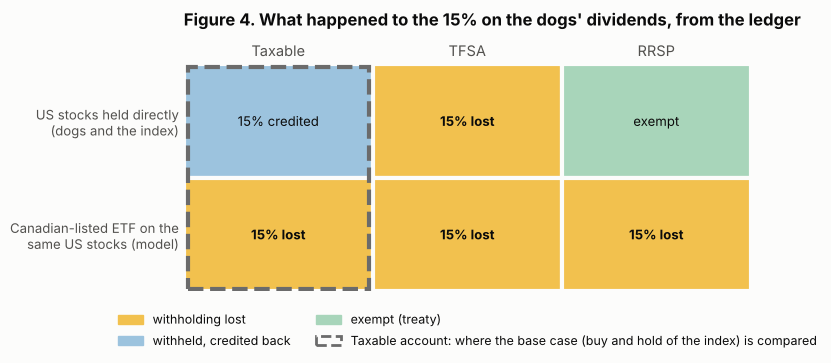

In [11]:
RATE = TC.rate_for("US")
def ledger_state(h, wr, a):
    r = W.loc[(h, wr, a)]
    return "lost" if r["lost"] > 0 else "credited" if r["credited"] > 0 else "exempt" if r["exempt"] > 0 else "none"
TEXT = {"lost": f"{RATE:.0%} withheld, LOST", "credited": f"{RATE:.0%} withheld, creditable (FTC)", "exempt": "EXEMPT (treaty)"}
CLASS = {DIRECT: "US stocks held directly\n(dogs and the index)", ETF: "Canadian-listed ETF on the\nsame US stocks (model)"}
doc = {DIRECT: treatment("direct", "US", RATE), ETF: treatment("fund", "US", RATE)}
def kind_of(text): return tp._treatment_kind(text)
agree = all(kind_of(doc[wr][a]) == ledger_state("dogs", wr, a) for wr in (DIRECT, ETF) for a in ACCOUNTS)
print("the ledger of the runs agrees with the documented matrix (docs/TAXES.md):", agree)
assert agree
ft = pd.DataFrame([dict(**{"class": CLASS[wr]}, **{a: TEXT[ledger_state("dogs", wr, a)] for a in ACCOUNTS}) for wr in (DIRECT, ETF)])
fig, ax = plt.subplots(figsize=(9, 3.6))
tp.withholding_matrix(ft, ax=ax, title="Figure 4. What happened to the 15% on the dogs' dividends, from the ledger",
                      legend=True, frame="taxable", frame_label="Taxable account: where the base case (buy and hold of the index) is compared")
fig.subplots_adjust(left=0.27, bottom=0.25); plt.show()

In [12]:
tt = REP["taxable"].tax["dogs"]
DOGS_DIVTAX, DOGS_GAINTAX = (tt["tax_dividends"] + tt["tax_foreign_dividends"]).sum(), tt["tax_capital_gains"].sum()
say(f"""
### What the evidence says

The ledger matched the documented matrix in every cell, and the rule it showed was that the same {RATE:.0%} is recovered, lost or never taken depending only on the account. Against the base case, buy and hold of the index in the same account, the dogs were hit hardest where the money cannot be recovered. In a taxable account no withholding was lost: the foreign tax credit returned {usd(dg("taxable", "credited"))} over the 33 years ({pts(dg("taxable", "credited_pts"))} points a year), against {usd(ix("taxable", "credited"))} ({pts(ix("taxable", "credited_pts"))} points a year) for the index, and the dogs left {pts(dg("taxable", "AfterTaxCAGR"))}% a year after tax against the index's {pts(ix("taxable", "AfterTaxCAGR"))}%, behind it by {pts(-dg("taxable", "vs_base"))} points; their tax drag was {pts(dg("taxable", "CAGR") - dg("taxable", "AfterTaxCAGR"))} points a year against {pts(ix("taxable", "CAGR") - ix("taxable", "AfterTaxCAGR"))}, of which {usd(DOGS_DIVTAX)} over the 33 years was tax on dividends (a US dividend is taxed as ordinary income at the marginal rate every year) and {usd(DOGS_GAINTAX)} tax on the gains their annual turnover realized. In a TFSA the dogs lost {usd(dg("tfsa", "lost"))} for good, {pts(dg("tfsa", "lost_pts"))} points a year against {pts(ix("tfsa", "lost_pts"))} for the index, and still left {pts(dg("tfsa", "AfterTaxCAGR"))}%, {pts(dg("tfsa", "vs_base"))} points ahead of the index in a TFSA. In an RRSP the treaty exempted {usd(dg("rrsp", "exempt"))}, nothing was lost, and the dogs left {pts(dg("rrsp", "AfterTaxCAGR"))}% after the withdrawal tax, {pts(dg("rrsp", "vs_base"))} points ahead of the index there. For a US stock held directly, the RRSP is the one account that takes no withholding and the TFSA the one that takes it for good; the taxable account takes it and gives it back.
""")
assert dg("taxable", "lost") == 0 and dg("tfsa", "lost") > 0 and dg("rrsp", "exempt") > 0 and dg("rrsp", "lost") == 0
assert dg("taxable", "vs_base") < 0 < dg("tfsa", "vs_base") and dg("rrsp", "vs_base") > 0


### What the evidence says

The ledger matched the documented matrix in every cell, and the rule it showed was that the same 15% is recovered, lost or never taken depending only on the account. Against the base case, buy and hold of the index in the same account, the dogs were hit hardest where the money cannot be recovered. In a taxable account no withholding was lost: the foreign tax credit returned \$320,426 over the 33 years (1.51 points a year), against \$53,389 (0.28 points a year) for the index, and the dogs left 8.66% a year after tax against the index's 8.95%, behind it by 0.28 points; their tax drag was 4.57 points a year against 0.65, of which \$752,127 over the 33 years was tax on dividends (a US dividend is taxed as ordinary income at the marginal rate every year) and \$123,178 tax on the gains their annual turnover realized. In a TFSA the dogs lost \$583,003 for good, 1.51 points a year against 0.28 for the index, and still left 11.48%, 2.20 points ahead of the index in a TFSA. In an RRSP the treaty exempted \$837,075, nothing was lost, and the dogs left 12.02% after the withdrawal tax, 3.60 points ahead of the index there. For a US stock held directly, the RRSP is the one account that takes no withholding and the TFSA the one that takes it for good; the taxable account takes it and gives it back.


## 3. The wrapper: the same dogs exposure through a US-listed or a Canadian-listed ETF

Section 2 held the US stocks directly, where the 15% is taken at source. The question now is what changes if the same exposure is held through an ETF, either listed in the US or listed in Canada. It follows from Section 2 because the dollars lost, credited and exempt there are the US-listed case; this section adds the Canadian-listed one and compares them in each account.

The panel has no ETFs, so this is a model of the same holdings: a copy of the dataset in which every name's `security_meta` is overridden. **US-listed ETF** is `wrapper="etf_us"`; the tax stage treats it exactly like the US stock itself (withholding at source, credit in a taxable account, exempt in an RRSP), which the next cell checks, so it is the same runs as Section 2. **Canadian-listed ETF** is `wrapper="etf_ca"` with `underlying_domicile="US"`: the fund pays the 15% inside, in every account, and the net distribution is taxed as foreign income. Its net asset value stays in US dollars, so the Canadian-dollar gain is identical and only the treatment of the withholding differs; no management fee is charged to either wrapper. **The base case is buy and hold of the index in the same account.**

In [13]:
snap = pd.DataFrame({"wrapper": ["stock", "etf_us"], "domicile": ["US", "US"], "currency": ["USD", "USD"]}, index=["STK", "ETF"])
fi = TC.foreign_info(["STK", "ETF"], snap)
same = bool((fi.loc["STK"] == fi.loc["ETF"]).all())
print("the tax stage treats wrapper etf_us and the US stock itself identically:", same)
assert same
t3 = W.reset_index()
t3 = t3[t3["holding"].isin([INDEX, "dogs"])].copy()
t3["row"] = np.where(t3["holding"] == INDEX, "Buy and hold the index (base)",
                     np.where(t3["wrapper"] == DIRECT, "Dogs, US-listed ETF (same as the stocks)", "Dogs, Canadian-listed ETF"))
t3["account"] = t3["account"].map(ACC_NAME)
t3 = t3.set_index(["row", "account"])[["AfterTaxCAGR", "vs_base", "lost", "credited", "exempt", "lost_pts"]]
t3.columns = ["Growth a year after tax", "After-tax growth minus the index in the same account", "Withholding lost ($)",
              "Credited back ($)", "Exempt ($)", "Lost (points a year)"]
t3 = t3.sort_index(level=1, key=lambda s: s.map({v: i for i, v in enumerate(ACC_NAME.values())}), sort_remaining=False)
print("Table 3. Same dogs exposure, two wrappers, by account, $100,000 started in 1990; the index rows are the base case")
t3.style.format({c: "{:.2%}" for c in (t3.columns[0], t3.columns[1], t3.columns[5])} | {c: "{:,.0f}" for c in t3.columns[2:5]})

the tax stage treats wrapper etf_us and the US stock itself identically: True
Table 3. Same dogs exposure, two wrappers, by account, $100,000 started in 1990; the index rows are the base case


,,Growth a year after tax,After-tax growth minus the index in the same account,Withholding lost ($),Credited back ($),Exempt ($),Lost (points a year)
row,account,,,,,,
Buy and hold the index (base),Taxable,8.95%,0.00%,0,"53,389",0,0.00%
"Dogs, US-listed ETF (same as the stocks)",Taxable,8.66%,-0.28%,0,"320,426",0,0.00%
"Dogs, Canadian-listed ETF",Taxable,7.63%,-1.32%,"260,011",0,0,1.51%
Buy and hold the index (base),TFSA,9.28%,0.00%,"57,233",0,0,0.28%
"Dogs, US-listed ETF (same as the stocks)",TFSA,11.48%,2.20%,"583,003",0,0,1.51%
"Dogs, Canadian-listed ETF",TFSA,11.48%,2.20%,"583,003",0,0,1.51%
Buy and hold the index (base),RRSP,8.42%,0.00%,0,0,"61,238",0.00%
"Dogs, US-listed ETF (same as the stocks)",RRSP,12.02%,3.60%,0,0,"837,075",0.00%
"Dogs, Canadian-listed ETF",RRSP,10.28%,1.87%,"583,003",0,0,1.51%


Figure 5 shows the after-tax growth of the dogs in each account and wrapper: the light bar is before tax (the same for both wrappers), the dark bar after tax, and the grey dashed mark is the base case, buy and hold of the index in that account. Figure 6 isolates the withholding: the points of growth a year it costs in each account, the amber bar for the US-listed ETF and the rust bar for the Canadian-listed one, with the index as the grey dashed mark. A bar at zero is not a missing bar: it means nothing was lost.

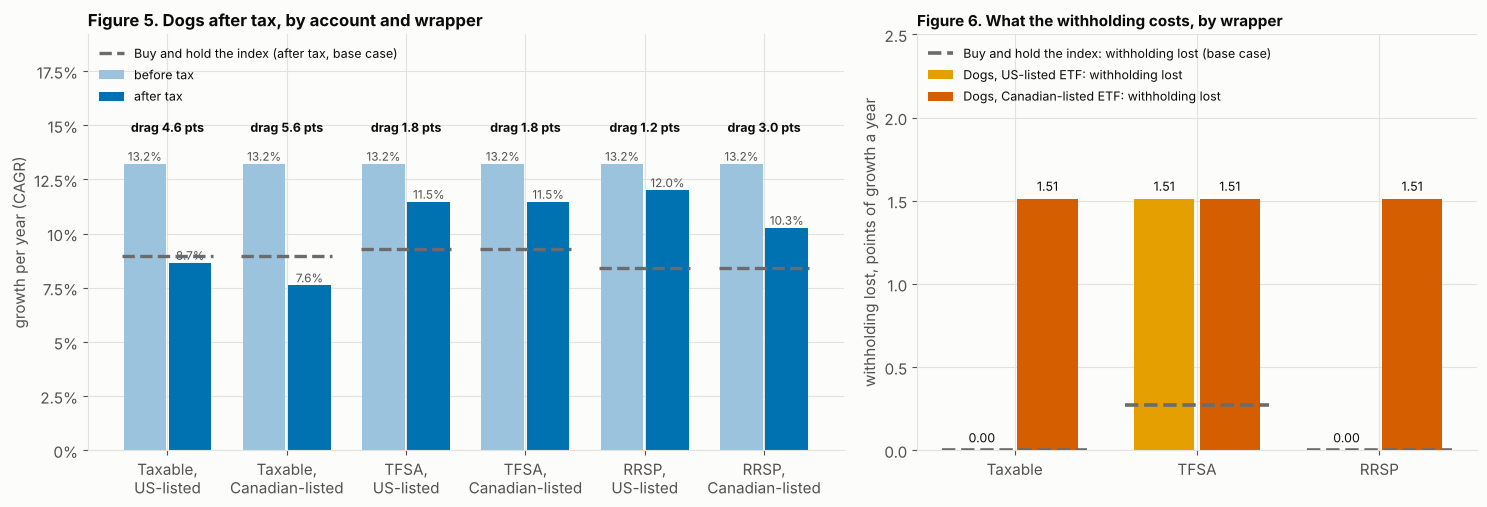

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw=dict(width_ratios=[1.35, 1]))
rows5 = [(f"{ACC_NAME[a]},\n{nm}", wr, a) for a in ACCOUNTS for nm, wr in (("US-listed", DIRECT), ("Canadian-listed", ETF))]
tab5 = pd.DataFrame([dict(label=lab_, CAGR=W.loc[("dogs", wr, a), "CAGR"], AfterTaxCAGR=W.loc[("dogs", wr, a), "AfterTaxCAGR"]) for lab_, wr, a in rows5])
tp.tax_drag_bars(tab5, ax=axes[0], baseline=[ix(a, "AfterTaxCAGR") for _, _, a in rows5], baseline_label="Buy and hold the index (after tax, base case)", legend=True,
                 title="Figure 5. Dogs after tax, by account and wrapper")
ax = tp._ax(axes[1])
x = np.arange(3); w = 0.36
for k, (wr, nm, col) in enumerate(((DIRECT, "US-listed ETF", "#E69F00"), (ETF, "Canadian-listed ETF", "#D55E00"))):
    v = np.array([W.loc[("dogs", wr, a), "lost_pts"] for a in ACCOUNTS]) * 100
    bars = ax.bar(x + (k - .5) * w, v, w * 0.92, color=col, label=f"Dogs, {nm}: withholding lost")
    for b_, y_ in zip(bars, v):
        ax.text(b_.get_x() + b_.get_width() / 2, y_ + 0.03, f"{y_:.2f}", ha="center", va="bottom", fontsize=9, color=tp.INK)
for i, a in enumerate(ACCOUNTS):
    v = ix(a, "lost_pts") * 100
    ax.plot([x[i] - 1.1 * w, x[i] + 1.1 * w], [v, v], color=GREY, ls="--", lw=2.6, zorder=4,
            label="Buy and hold the index: withholding lost (base case)" if i == 0 else None)
ax.set_xticks(x, [ACC_NAME[a] for a in ACCOUNTS]); ax.set_ylabel("withholding lost, points of growth a year"); ax.set_ylim(0, 2.5)
ax.set_title("Figure 6. What the withholding costs, by wrapper", loc="left", fontsize=11, fontweight="bold")
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout(); plt.show()

In [15]:
gap = {a: dg(a, "AfterTaxCAGR") - et(a, "AfterTaxCAGR") for a in ACCOUNTS}
say(f"""
### What the evidence says

The wrapper decides whether the 15% is a cost at all. Held through a US-listed ETF the dogs lost {usd(dg("taxable", "lost"))} in a taxable account, {usd(dg("tfsa", "lost"))} in a TFSA and {usd(dg("rrsp", "lost"))} in an RRSP; held through a Canadian-listed ETF on the same stocks they lost {usd(et("taxable", "lost"))}, {usd(et("tfsa", "lost"))} and {usd(et("rrsp", "lost"))}, {pts(et("taxable", "lost_pts"))} points a year in every account. The Canadian-listed wrapper therefore cost {pts(gap["taxable"])} points of after-tax growth a year in a taxable account, {pts(gap["tfsa"])} in a TFSA, where both wrappers lose the money, and {pts(gap["rrsp"])} in an RRSP, where the US-listed one loses nothing. Against the base case, buy and hold of the index in the same account, whose lost withholding is {pts(ix("tfsa", "lost_pts"))} points a year in a TFSA, the Canadian-listed dogs trailed the index after tax by {pts(-et("taxable", "vs_base"))} points a year in a taxable account, while the US-listed dogs trailed by {pts(-dg("taxable", "vs_base"))}. The model charges no management fee and the fund's net asset value is assumed gross of withholding, so the comparison isolates the withholding only; a real Canadian-listed ETF has a fee, a currency-hedging choice and a net asset value already net of the 15%.
""")
assert abs(gap["tfsa"]) < 1e-9 and gap["rrsp"] > 0 and gap["taxable"] > 0


### What the evidence says

The wrapper decides whether the 15% is a cost at all. Held through a US-listed ETF the dogs lost \$0 in a taxable account, \$583,003 in a TFSA and \$0 in an RRSP; held through a Canadian-listed ETF on the same stocks they lost \$260,011, \$583,003 and \$583,003, 1.51 points a year in every account. The Canadian-listed wrapper therefore cost 1.04 points of after-tax growth a year in a taxable account, 0.00 in a TFSA, where both wrappers lose the money, and 1.74 in an RRSP, where the US-listed one loses nothing. Against the base case, buy and hold of the index in the same account, whose lost withholding is 0.28 points a year in a TFSA, the Canadian-listed dogs trailed the index after tax by 1.32 points a year in a taxable account, while the US-listed dogs trailed by 0.28. The model charges no management fee and the fund's net asset value is assumed gross of withholding, so the comparison isolates the withholding only; a real Canadian-listed ETF has a fee, a currency-hedging choice and a net asset value already net of the 15%.


## 4. Currency and the cost base on real history

Sections 2 and 3 took the tax on dividends as given in US dollars; the question now is what the exchange rate does to the gain the CRA taxes, year by year, on the dogs portfolio's real trades. It follows from Section 3 because the same trades are replayed twice, in a taxable account, with taxes paid from outside the account so that both runs hold exactly the same dollars: once on the **Canadian-dollar basis** (each purchase and dividend enters the cost base at that day's USDCAD, each sale is converted at its day's rate, the series loaded in `TaxConfig(macro=lab.macro)`) and once with the currency ignored, which is what happens with no FX series loaded (the library then prints the warning shown below).

**The base case here is the same trades taxed in US dollars, the currency ignored**, and beside it buy and hold of the index sold on the last day. The library taxes the passive index in US dollars only, because it has no trades to convert, so the index's Canadian-dollar cost base is rebuilt in the notebook from the library's own dividend stream and checked against its US-dollar gain.

In [16]:
print("library warning when no FX series is loaded:", FX_NOTE)
assert FX_NOTE == FX_WARNING
yrs_all = list(G["dogs"].index)
rows = []
for l in SCREENS:
    c = CUR[l]
    rows.append(dict(holding=("Dogs" if l == "dogs" else "Momentum 12 months"), basis="Canadian dollars (the CRA basis)", cagr=c["cad_cagr"], net=c["net_cad"], flips=c["flips"],
                     gtax=c["gtax_cad"], sale=c["sell_cad"] - c["tax_cad"], total=c["sell_cad"]))
    rows.append(dict(holding=("Dogs" if l == "dogs" else "Momentum 12 months"), basis="US dollars (currency ignored, base)", cagr=c["usd_cagr"], net=c["net_usd"], flips=np.nan,
                     gtax=c["gtax_usd"], sale=c["sell_usd"] - c["tax_usd"], total=c["sell_usd"]))
rows.append(dict(holding="Buy and hold the index (base)", basis="Canadian dollars (rebuilt here)", cagr=CUR[INDEX]["cad_cagr"], net=0.0, flips=np.nan, gtax=0.0, sale=IDX_CAD_TAX, total=np.nan))
rows.append(dict(holding="Buy and hold the index (base)", basis="US dollars (the library)", cagr=CUR[INDEX]["usd_cagr"], net=0.0, flips=np.nan, gtax=0.0, sale=IDX_USD_TAX, total=np.nan))
t4 = pd.DataFrame(rows).set_index(["holding", "basis"])
t4.columns = ["Growth a year before tax", "Net gain realized during the run ($)", "Years the sign flipped", "Capital gains tax during the run ($)",
              "Tax on the sale on the last day ($)", "All tax over 33 years, with the final sale ($)"]
print("Table 4. The same trades on two bases, taxable account, $100,000 started in 1990, taxes paid from outside the account")
t4.style.format({"Growth a year before tax": "{:.2%}"} | {c: "{:,.0f}" for c in t4.columns[1:] if c != "Years the sign flipped"} | {"Years the sign flipped": "{:.0f}"}, na_rep="")

library warning when no FX series is loaded: foreign gains taxed in portfolio currency; load an FX series for CAD basis
Table 4. The same trades on two bases, taxable account, $100,000 started in 1990, taxes paid from outside the account


Figure 7 shows what the exchange rate did in each year and in each stretch of the 33 years. The bars are the change in USDCAD over the calendar year (blue when the US dollar rose against the Canadian dollar, which adds to a US-dollar gain in Canadian dollars; amber when it fell); the shaded bands are the five stretches of Table 5, and the grey dashed line is the base case, the cumulative effect of the exchange rate on buy and hold of the index, the index's value in Canadian dollars relative to US dollars.

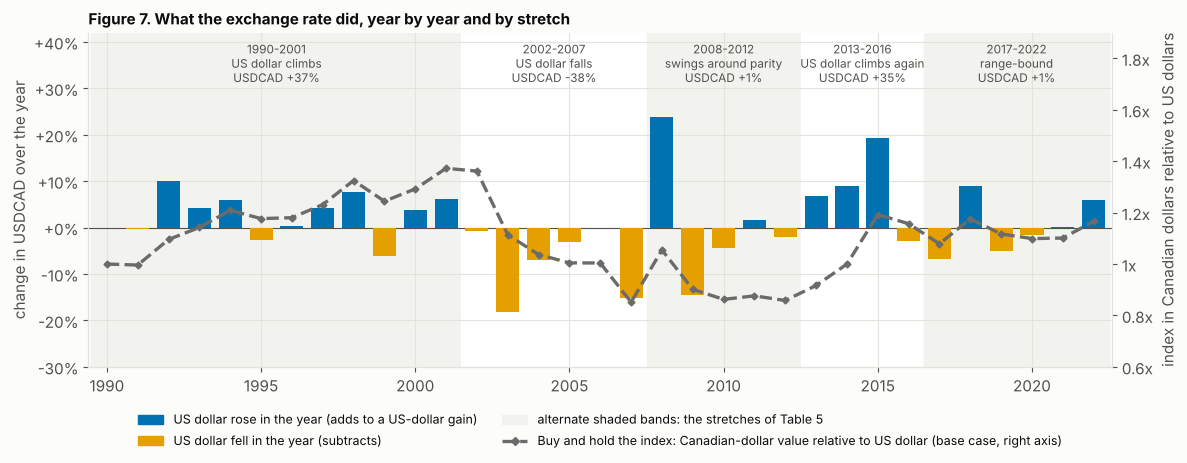

In [17]:
ye_full = fx.groupby(fx.index.year).last()
chg = pd.Series({y: (ye_full.loc[y] / (ye_full.loc[y - 1] if (y - 1) in ye_full.index else FX0) - 1) for y in ye_full.index})
fig, ax = plt.subplots(figsize=(12, 4.8))
ax = tp._ax(ax)
for (p, a_, b_, wh), shade in zip(PERIODS, ("#F2F2EE", "#FFFFFF", "#F2F2EE", "#FFFFFF", "#F2F2EE")):
    ax.axvspan(a_ - 0.5, b_ + 0.5, color=shade, zorder=0)
    ax.text((a_ + b_) / 2, 0.40, f"{p}\n{wh}\nUSDCAD {PER.loc[p, 'usdcad_change']:+.0%}", ha="center", va="top", fontsize=8.5, color=tp.INK2)
ax.bar(chg.index, chg.to_numpy(), 0.75, color=np.where(chg.to_numpy() >= 0, "#0072B2", "#E69F00"), zorder=3)
ax.axhline(0, color=tp.INK2, lw=0.8)
ax.set_ylim(-0.30, 0.42); ax.set_xlim(1989.4, 2022.6)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:+.0%}")
ax.set_ylabel("change in USDCAD over the year")
ax2 = ax.twinx(); ax2.spines["right"].set_visible(True); ax2.grid(False)
cumfx = ye_full / FX0
ax2.plot(cumfx.index, cumfx.to_numpy(), color=GREY, ls="--", lw=2.4, marker="D", ms=3.5, zorder=5)
ax2.set_ylabel("index in Canadian dollars relative to US dollars"); ax2.set_ylim(0.6, 1.9)
ax2.yaxis.set_major_formatter(lambda v, _: f"{v:g}x")
ax.set_title("Figure 7. What the exchange rate did, year by year and by stretch", loc="left", fontsize=11, fontweight="bold")
ax.legend(handles=[Patch(color="#0072B2", label="US dollar rose in the year (adds to a US-dollar gain)"),
                   Patch(color="#E69F00", label="US dollar fell in the year (subtracts)"),
                   Patch(color="#F2F2EE", label="alternate shaded bands: the stretches of Table 5"),
                   Line2D([], [], color=GREY, ls="--", lw=2.4, marker="D", ms=4, label="Buy and hold the index: Canadian-dollar value relative to US dollar (base case, right axis)")],
          loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=9, frameon=False)
fig.tight_layout(); plt.show()

Figure 8 compares the two bases on the dogs' own trades. On the left, each year has a pair of bars: the net gain the dogs realized that year in Canadian dollars (blue) next to the same trades with the currency ignored (grey, the base case), as a percentage of the portfolio's value at the start of that year, so that the early years can be seen beside the late ones; a red cross marks the years in which one basis shows a gain and the other a loss. On the right, the gain realized by selling everything on the last day, in Canadian dollars (blue) and US dollars (grey, the base), in thousands of dollars on \$100,000 started in 1990, for the dogs and for buy and hold of the index.

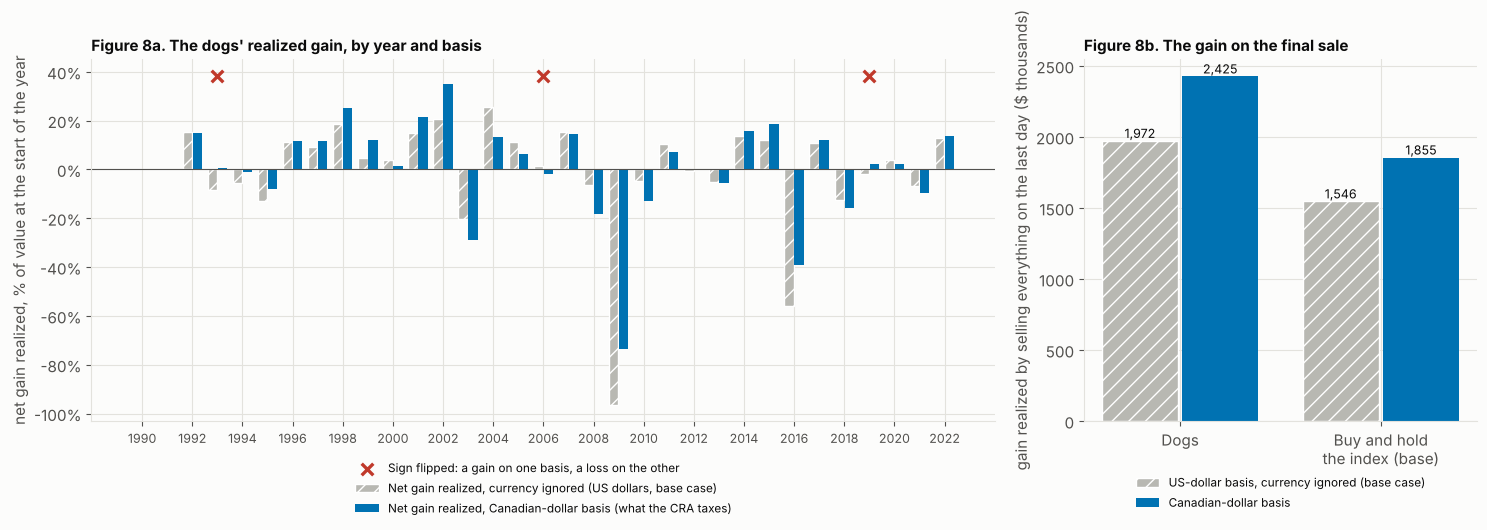

In [18]:
g = G["dogs"]
wealth0 = REP_CAD.tax["dogs"]["wealth_pre_tax"].shift(1).fillna(CAP)              # portfolio value at the start of each year
pct_cad, pct_usd = 100 * g["net_cad"] / wealth0, 100 * g["net_usd"] / wealth0
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw=dict(width_ratios=[2.3, 1]))
ax = tp._ax(axes[0])
x = np.arange(len(g)); w = 0.4
ax.bar(x - w / 2, pct_usd.to_numpy(), w * 0.94, color="#B8B8B2", hatch="//", edgecolor="white", label="Net gain realized, currency ignored (US dollars, base case)")
ax.bar(x + w / 2, pct_cad.to_numpy(), w * 0.94, color="#0072B2", label="Net gain realized, Canadian-dollar basis (what the CRA taxes)")
top = max(pct_cad.max(), pct_usd.max())
fl = g["flip"].to_numpy()
ax.scatter(x[fl], np.full(fl.sum(), top * 1.1), marker="x", s=70, color="#C0392B", lw=2.4, zorder=5, label="Sign flipped: a gain on one basis, a loss on the other")
ax.axhline(0, color=tp.INK2, lw=0.8)
ax.set_xticks(x[::2], [str(y) for y in g.index[::2]], fontsize=9)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:g}%")
ax.set_ylabel("net gain realized, % of value at the start of the year")
ax.set_title("Figure 8a. The dogs' realized gain, by year and basis", loc="left", fontsize=11, fontweight="bold")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), fontsize=8.5, frameon=False)
ax = tp._ax(axes[1])
groups = [("Dogs", CUR["dogs"]["gain_cad"], CUR["dogs"]["gain_usd"]), ("Buy and hold\nthe index (base)", IDX_CAD_GAIN, IDX_USD_GAIN)]
for i, (nm, c_, u_) in enumerate(groups):
    ax.bar(i - 0.2, u_ / 1e3, 0.38, color="#B8B8B2", hatch="//", edgecolor="white", label="US-dollar basis, currency ignored (base case)" if i == 0 else None)
    ax.bar(i + 0.2, c_ / 1e3, 0.38, color="#0072B2", label="Canadian-dollar basis" if i == 0 else None)
    ax.text(i - 0.2, u_ / 1e3, f"{u_ / 1e3:,.0f}", ha="center", va="bottom", fontsize=9); ax.text(i + 0.2, c_ / 1e3, f"{c_ / 1e3:,.0f}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(range(2), [g_[0] for g_ in groups]); ax.set_ylabel("gain realized by selling everything on the last day ($ thousands)")
ax.set_title("Figure 8b. The gain on the final sale", loc="left", fontsize=11, fontweight="bold")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=8.5, frameon=False)
fig.tight_layout(); plt.show()

In [19]:
t5 = PER.copy()
t5.loc["All 33 years"] = [ "", fx_change(1990, 2022), PER["net_cad"].sum(), PER["net_usd"].sum(), PER["flips"].sum(), PER["tax_cad"].sum(), PER["tax_usd"].sum()]
t5["Tax difference ($)"] = t5["tax_cad"] - t5["tax_usd"]
t5 = t5[["what", "usdcad_change", "net_usd", "net_cad", "flips", "tax_usd", "tax_cad", "Tax difference ($)"]]
t5.columns = ["What USDCAD did", "USDCAD change", "Dogs: net gain, US dollars (base) ($)", "Dogs: net gain, Canadian dollars ($)", "Years the sign flipped",
              "Tax, US dollars (base) ($)", "Tax, Canadian dollars ($)", "Tax difference ($)"]
print("Table 5. By stretch of USDCAD, the dogs on both bases (tax paid in the year, before the final sale)")
t5.style.format({"USDCAD change": "{:+.1%}", "Years the sign flipped": "{:.0f}"} | {c: "{:,.0f}" for c in t5.columns[2:] if c != "Years the sign flipped"})

Table 5. By stretch of USDCAD, the dogs on both bases (tax paid in the year, before the final sale)


,What USDCAD did,USDCAD change,"Dogs: net gain, US dollars (base) ($)","Dogs: net gain, Canadian dollars ($)",Years the sign flipped,"Tax, US dollars (base) ($)","Tax, Canadian dollars ($)",Tax difference ($)
period,,,,,,,,
1990-2001,US dollar climbs,+37.2%,"202,175","313,239",1,"130,800","176,142","45,342"
2002-2007,US dollar falls,-38.0%,"809,811","589,352",1,"471,861","442,439","-29,422"
2008-2012,swings around parity,+0.8%,"-951,232","-1,162,019",0,"398,668","342,130","-56,538"
2013-2016,US dollar climbs again,+34.8%,"-670,128","24,689",0,"507,812","531,709","23,897"
2017-2022,range-bound,+0.8%,"459,557","400,394",1,"806,379","916,198","109,819"
All 33 years,,+16.6%,"-149,817","165,655",3,"2,315,519","2,408,617","93,098"


In [20]:
g = G["dogs"]; c_ = CUR["dogs"]
sell_tax_cad, sell_tax_usd = c_["sell_cad"] - c_["tax_cad"], c_["sell_usd"] - c_["tax_usd"]
worst = g.loc[g["tax_cad"].sub(g["tax_usd"]).abs().idxmax()]
say(f"""
### What the evidence says

The cost base fixed in Canadian dollars changed what the dogs' trades looked like to the CRA, and not by a rounding error. Over the 33 years the dogs realized a net {usd(c_["net_cad"])} on the Canadian-dollar basis against {usd(c_["net_usd"])} on the base case, the same trades with the currency ignored; the sign of the year's net gain differed between the two bases in {c_["flips"]} years ({", ".join(str(y) for y in c_["flip_years"])}), and in {int((g["net_cad"] > g["net_usd"]).sum())} of the 33 years the Canadian-dollar basis showed the larger gain. The currency helped most in the stretches when the US dollar climbed (Table 5: {PER.loc["1990-2001", "usdcad_change"]:+.0%} in 1990-2001 and {PER.loc["2013-2016", "usdcad_change"]:+.0%} in 2013-2016, where the Canadian-dollar net gains were {usd(PER.loc["1990-2001", "net_cad"] - PER.loc["1990-2001", "net_usd"])} and {usd(PER.loc["2013-2016", "net_cad"] - PER.loc["2013-2016", "net_usd"])} above the base) and hurt when it fell ({PER.loc["2002-2007", "usdcad_change"]:+.0%} in 2002-2007, {usd(PER.loc["2002-2007", "net_cad"] - PER.loc["2002-2007", "net_usd"])} against the base). Counting dividends, capital gains and the sale on the last day, the 33 years cost {usd(c_["sell_cad"])} on the Canadian-dollar basis against {usd(c_["sell_usd"])} in US dollars, {usd(c_["sell_cad"] - c_["sell_usd"])} more: {usd(sell_tax_cad - sell_tax_usd)} from the final sale, {usd(c_["gtax_cad"] - c_["gtax_usd"])} from capital gains tax during the run, and {usd(c_["sell_cad"] - c_["sell_usd"] - (sell_tax_cad - sell_tax_usd) - (c_["gtax_cad"] - c_["gtax_usd"]))} from dividends taxed at their converted amounts and from the timing of refunds. The largest single year's difference was {usd(abs(worst["tax_cad"] - worst["tax_usd"]))} in {int(worst.name)}. The base case, the index sold on the last day, shows the same direction: a taxable gain of {usd(IDX_CAD_GAIN)} in Canadian dollars against {usd(IDX_USD_GAIN)} in US dollars, {usd(IDX_CAD_TAX - IDX_USD_TAX)} more tax, because the US dollar ended {FX1 / FX0 - 1:+.0%} above its buy-day value. An analysis that ignored the exchange rate would have understated the dogs' tax by {usd(c_["sell_cad"] - c_["sell_usd"])} and the index's sale tax by {usd(IDX_CAD_TAX - IDX_USD_TAX)}, and would have shown the dogs' 33-year net gain as {usd(c_["net_usd"])} when the CRA's basis shows {usd(c_["net_cad"])}.
""")
assert c_["flips"] >= 1 and c_["sell_cad"] > c_["sell_usd"] and IDX_CAD_GAIN > IDX_USD_GAIN and c_["net_cad"] * c_["net_usd"] < 0


### What the evidence says

The cost base fixed in Canadian dollars changed what the dogs' trades looked like to the CRA, and not by a rounding error. Over the 33 years the dogs realized a net \$165,655 on the Canadian-dollar basis against -\$149,817 on the base case, the same trades with the currency ignored; the sign of the year's net gain differed between the two bases in 3 years (1993, 2006, 2019), and in 17 of the 33 years the Canadian-dollar basis showed the larger gain. The currency helped most in the stretches when the US dollar climbed (Table 5: +37% in 1990-2001 and +35% in 2013-2016, where the Canadian-dollar net gains were \$111,064 and \$694,817 above the base) and hurt when it fell (-38% in 2002-2007, -\$220,459 against the base). Counting dividends, capital gains and the sale on the last day, the 33 years cost \$2,562,663 on the Canadian-dollar basis against \$2,315,519 in US dollars, \$247,144 more: \$154,046 from the final sale, \$13,606 from capital gains tax during the run, and \$79,492 from dividends taxed at their converted amounts and from the timing of refunds. The largest single year's difference was \$60,274 in 2008. The base case, the index sold on the last day, shows the same direction: a taxable gain of \$1,854,844 in Canadian dollars against \$1,546,005 in US dollars, \$74,121 more tax, because the US dollar ended +17% above its buy-day value. An analysis that ignored the exchange rate would have understated the dogs' tax by \$247,144 and the index's sale tax by \$74,121, and would have shown the dogs' 33-year net gain as -\$149,817 when the CRA's basis shows \$165,655.


## 5. The same questions for momentum_12m, briefly

Sections 2 to 4 used the dogs, which have a high yield and a heavy turnover of obscure, distressed names. The question is whether the answers change for a screen with a low yield. It follows from Section 4 because the same two measurements, withholding by account and the Canadian-dollar against US-dollar basis, are repeated for `momentum_12m` (the stocks with the best 12-month price return, held for a year). **The base case is buy and hold of the index in the same account.** Table 6 has one row per account and, below, the currency measurements; there is no chart because the screen's yield is close to the index's and every bar would sit next to the grey mark.

In [21]:
rows = []
for a in ACCOUNTS:
    rows.append({"Account": ACC_NAME[a], "Holding": "Buy and hold the index (base)", "Growth a year after tax": ix(a, "AfterTaxCAGR"),
                 "After-tax growth minus the index": 0.0, "Withholding lost ($)": ix(a, "lost"), "Credited back ($)": ix(a, "credited"),
                 "Exempt ($)": ix(a, "exempt"), "Lost (points a year)": ix(a, "lost_pts")})
    rows.append({"Account": ACC_NAME[a], "Holding": "momentum_12m", "Growth a year after tax": mo(a, "AfterTaxCAGR"),
                 "After-tax growth minus the index": mo(a, "vs_base"), "Withholding lost ($)": mo(a, "lost"), "Credited back ($)": mo(a, "credited"),
                 "Exempt ($)": mo(a, "exempt"), "Lost (points a year)": mo(a, "lost_pts")})
t6 = pd.DataFrame(rows).set_index(["Account", "Holding"])
print("Table 6a. momentum_12m and the index, withholding by account, $100,000 started in 1990, taxes paid from the account as in Section 2")
display(t6.style.format({c: "{:.2%}" for c in ("Growth a year after tax", "After-tax growth minus the index", "Lost (points a year)")} |
                        {c: "{:,.0f}" for c in ("Withholding lost ($)", "Credited back ($)", "Exempt ($)")}))
m_ = CUR["momentum_12m"]
t6b = pd.DataFrame({"Buy and hold the index (base)": [CUR[INDEX]["usd_cagr"], CUR[INDEX]["cad_cagr"], np.nan, np.nan, np.nan, IDX_USD_GAIN, IDX_CAD_GAIN],
                    "momentum_12m": [m_["usd_cagr"], m_["cad_cagr"], m_["net_usd"], m_["net_cad"], m_["flips"], m_["gain_usd"], m_["gain_cad"]]},
                   index=["Growth a year before tax, US dollars", "Growth a year before tax, Canadian dollars", "Net gain realized during the run, US dollars ($)",
                          "Net gain realized during the run, Canadian dollars ($)", "Years the sign flipped", "Gain on the sale on the last day, US dollars ($)",
                          "Gain on the sale on the last day, Canadian dollars ($)"])
t6b.loc["Tax over 33 years with the final sale, US dollars ($)"] = [np.nan, m_["sell_usd"]]
t6b.loc["Tax over 33 years with the final sale, Canadian dollars ($)"] = [np.nan, m_["sell_cad"]]
print("Table 6b. momentum_12m, Canadian-dollar basis against US-dollar basis, taxable account, taxes paid from outside the account as in Section 4 (the index's gains are rebuilt as in Section 4)")
t6b.style.format("{:,.0f}", na_rep="").format("{:.2%}", subset=pd.IndexSlice[t6b.index[:2], :]).format("{:.0f}", subset=pd.IndexSlice[["Years the sign flipped"], :], na_rep="")

Table 6a. momentum_12m and the index, withholding by account, $100,000 started in 1990, taxes paid from the account as in Section 2


Table 6b. momentum_12m, Canadian-dollar basis against US-dollar basis, taxable account, taxes paid from outside the account as in Section 4 (the index's gains are rebuilt as in Section 4)


,Buy and hold the index (base),momentum_12m
"Growth a year before tax, US dollars",9.59%,8.94%
"Growth a year before tax, Canadian dollars",10.11%,9.45%
"Net gain realized during the run, US dollars ($)",,"1,423,015"
"Net gain realized during the run, Canadian dollars ($)",,"1,579,562"
Years the sign flipped,,2
"Gain on the sale on the last day, US dollars ($)","1,546,005","889,531"
"Gain on the sale on the last day, Canadian dollars ($)","1,854,844","1,059,315"
"Tax over 33 years with the final sale, US dollars ($)",,"302,892"
"Tax over 33 years with the final sale, Canadian dollars ($)",,"365,870"


In [22]:
MOM_GAINTAX = REP["taxable"].tax["momentum_12m"]["tax_capital_gains"].sum()
say(f"""
### What the evidence says

Withholding was small for the momentum screen: {pts(mo("tfsa", "lost_pts"))} points a year lost in a TFSA against {pts(ix("tfsa", "lost_pts"))} for the index, {usd(mo("tfsa", "lost"))} over the 33 years, and {usd(mo("taxable", "credited"))} credited back in a taxable account against {usd(ix("taxable", "credited"))}. After tax it left {pts(mo("taxable", "AfterTaxCAGR"))}% a year in a taxable account, {pts(-mo("taxable", "vs_base"))} points behind the index, and it trailed the index after tax in the TFSA ({spts(mo("tfsa", "vs_base"))} points) and the RRSP ({spts(mo("rrsp", "vs_base"))}) as well; it paid {usd(MOM_GAINTAX)} of tax on the gains its turnover realized, which buy and hold defers to the sale. The currency was the larger effect: the Canadian-dollar basis showed a net realized gain of {usd(m_["net_cad"])} against {usd(m_["net_usd"])} in US dollars, with {m_["flips"]} years of opposite sign ({", ".join(str(y) for y in m_["flip_years"])}), and the 33 years of tax with the final sale were {usd(m_["sell_cad"])} against {usd(m_["sell_usd"])}, {usd(m_["sell_cad"] - m_["sell_usd"])} more. Against the base case, the index, the answer from Section 4 holds for a low-yield screen as well: withholding is a minor cost, and the exchange rate is what changes the tax.
""")
assert mo("tfsa", "lost_pts") < dg("tfsa", "lost_pts") and all(mo(a, "vs_base") < 0 for a in ACCOUNTS)


### What the evidence says

Withholding was small for the momentum screen: 0.09 points a year lost in a TFSA against 0.28 for the index, \$14,567 over the 33 years, and \$12,729 credited back in a taxable account against \$53,389. After tax it left 7.97% a year in a taxable account, 0.97 points behind the index, and it trailed the index after tax in the TFSA (-0.43 points) and the RRSP (-0.65) as well; it paid \$354,016 of tax on the gains its turnover realized, which buy and hold defers to the sale. The currency was the larger effect: the Canadian-dollar basis showed a net realized gain of \$1,579,562 against \$1,423,015 in US dollars, with 2 years of opposite sign (1993, 2019), and the 33 years of tax with the final sale were \$365,870 against \$302,892, \$62,978 more. Against the base case, the index, the answer from Section 4 holds for a low-yield screen as well: withholding is a minor cost, and the exchange rate is what changes the tax.


## 6. Reading guide: what is real, what is approximate, and the licence

The question is how far these numbers can be trusted and where they stop. It follows from the five sections before it, each of which rests on the same data and the same tax model, so the limits below apply to all of them. **The base case throughout was buy and hold of the index in the same account** (in Section 4, the same trades taxed in US dollars beside the index sold on the last day), and the reading guide says where that base case is itself approximate.

In [23]:
say(f"""
**What is real.** The prices and the membership of the index on each date, including the {card.n_delisted:,} delisted names; each stock's cash dividends on the dates they were paid (the panel drops a dividend above 25% of the close and a repeated dividend within 20 days, and counts both on the data card in Section 1); the daily USDCAD from the Federal Reserve (H.10, with the days without a quote filled forward); and the index total return, the daily S&P 500 level with Shiller's monthly dividend yield added back. The screens (`dogs`, `momentum_12m`) are the library's own with the market-cap cut removed, because the panel has no market cap: `dogs` here is the ten highest trailing yields of the whole S&P 500, not of the 30 largest.

**What is approximate.**

* **The tax tables are 2025's, applied to every year from 1990 to 2022**, with a fixed Alberta salary of \\$90,000. The library reports "{TAX_NOTE.split(": ", 1)[1]}" for the earlier years. Historical rates differed (and the inclusion rate of capital gains was not always one half), so the dollars are what the 2025 rules would charge on the 1990-2022 events, not what was charged.
* **The delisting haircut.** A name whose prices end takes a loss of 30% at its last price. That is harsh for a takeover paid at a premium and generous for a bankruptcy, and it creates realized losses that shape the capital gains results.
* **Trailing-yield distress names.** The yield is the last 365 days of dividends over today's price, so a stock whose price collapsed shows a very high yield. The dogs buy such names (AIG and Fannie Mae in 2008 and 2009), which is part of why their worst fall is {pts(-REP["taxable"].table.loc["dogs", "MaxDD"])}% and why their withholding is larger than a sound high-yield portfolio's would be. The tax stage also takes the yield seen at each rebalance and pays it pro rata until the next one, not on the real dividend dates.
* **The Canadian-listed ETF is a model of the same holdings.** It reuses the stocks' prices and dividends, takes the 15% inside the fund, charges no management fee and keeps its net asset value in US dollars. Real ETFs differ: fees, a net asset value already net of withholding, hedged versions, and holdings that are the index and not the dogs. The US-listed ETF is the US stocks held directly.
* **The index is taxed in US dollars by the library.** Its Canadian-dollar cost base in Section 4 was rebuilt in the notebook from the library's own dividend stream and checked against the library's US-dollar gain; the tax on the index's dividends stays in US dollars.
* **Taxes paid from the account (Sections 2, 3 and 5) or from outside it (Section 4).** The first shrinks the account and so the later dollars; the second keeps both bases on exactly the same dollars so that only the basis differs.

**What it ignores.** Contribution room, the RRSP deduction refund, AMT, T1135 reporting above \\$100,000 of foreign property outside registered accounts, US estate tax, and the cost of exchanging currency.

**Licence.** The panel (`Johnbrick123/sp500-data`, CRSP-derived for 1968-2006, then Yahoo, Tiingo and Quandl WIKI) states no licence. You download it with `make data-panel` into the git-ignored `screenlab/data/panel/` for local use; it is not redistributed, and the saved outputs of this notebook embed figures derived from it, so keep the executed notebook local. The USDCAD, CPI and 10-year series are committed mirrors of public-domain Federal Reserve and BLS data (`data/mirrors/SOURCES.md`).
""")


**What is real.** The prices and the membership of the index on each date, including the 631 delisted names; each stock's cash dividends on the dates they were paid (the panel drops a dividend above 25% of the close and a repeated dividend within 20 days, and counts both on the data card in Section 1); the daily USDCAD from the Federal Reserve (H.10, with the days without a quote filled forward); and the index total return, the daily S&P 500 level with Shiller's monthly dividend yield added back. The screens (`dogs`, `momentum_12m`) are the library's own with the market-cap cut removed, because the panel has no market cap: `dogs` here is the ten highest trailing yields of the whole S&P 500, not of the 30 largest.

**What is approximate.**

* **The tax tables are 2025's, applied to every year from 1990 to 2022**, with a fixed Alberta salary of \$90,000. The library reports "no tax table, used 2025" for the earlier years. Historical rates differed (and the inclusion rate of capital gains was not always one half), so the dollars are what the 2025 rules would charge on the 1990-2022 events, not what was charged.
* **The delisting haircut.** A name whose prices end takes a loss of 30% at its last price. That is harsh for a takeover paid at a premium and generous for a bankruptcy, and it creates realized losses that shape the capital gains results.
* **Trailing-yield distress names.** The yield is the last 365 days of dividends over today's price, so a stock whose price collapsed shows a very high yield. The dogs buy such names (AIG and Fannie Mae in 2008 and 2009), which is part of why their worst fall is 83.33% and why their withholding is larger than a sound high-yield portfolio's would be. The tax stage also takes the yield seen at each rebalance and pays it pro rata until the next one, not on the real dividend dates.
* **The Canadian-listed ETF is a model of the same holdings.** It reuses the stocks' prices and dividends, takes the 15% inside the fund, charges no management fee and keeps its net asset value in US dollars. Real ETFs differ: fees, a net asset value already net of withholding, hedged versions, and holdings that are the index and not the dogs. The US-listed ETF is the US stocks held directly.
* **The index is taxed in US dollars by the library.** Its Canadian-dollar cost base in Section 4 was rebuilt in the notebook from the library's own dividend stream and checked against the library's US-dollar gain; the tax on the index's dividends stays in US dollars.
* **Taxes paid from the account (Sections 2, 3 and 5) or from outside it (Section 4).** The first shrinks the account and so the later dollars; the second keeps both bases on exactly the same dollars so that only the basis differs.

**What it ignores.** Contribution room, the RRSP deduction refund, AMT, T1135 reporting above \$100,000 of foreign property outside registered accounts, US estate tax, and the cost of exchanging currency.

**Licence.** The panel (`Johnbrick123/sp500-data`, CRSP-derived for 1968-2006, then Yahoo, Tiingo and Quandl WIKI) states no licence. You download it with `make data-panel` into the git-ignored `screenlab/data/panel/` for local use; it is not redistributed, and the saved outputs of this notebook embed figures derived from it, so keep the executed notebook local. The USDCAD, CPI and 10-year series are committed mirrors of public-domain Federal Reserve and BLS data (`data/mirrors/SOURCES.md`).


In [24]:
say(f"""
### What the evidence says

Taken together, the real data answer the four questions this notebook asked, each against its base case. Withholding is a cost of the wrapper and the account more than of the stock: on the dogs it was {pts(dg("tfsa", "lost_pts"))} points a year in a TFSA and {pts(et("taxable", "lost_pts"))} in any account through a Canadian-listed ETF, against {pts(ix("tfsa", "lost_pts"))} for the index in a TFSA, and zero in an RRSP or a taxable account for US stocks held directly. The currency is a cost-base effect that moves the tax in particular years more than it moves the 33-year growth: it added {pts(CUR[INDEX]["cad_cagr"] - CUR[INDEX]["usd_cagr"])} points a year to the index and changed the sign of the dogs' realized gain in {CUR["dogs"]["flips"]} years. The numbers are whatever 1990 to 2022 happened to give, with 2025 tax rules; a different 33 years, or the tax rules of the time, would give different dollars and, for the currency, possibly a different sign. Not tax advice.
""")


### What the evidence says

Taken together, the real data answer the four questions this notebook asked, each against its base case. Withholding is a cost of the wrapper and the account more than of the stock: on the dogs it was 1.51 points a year in a TFSA and 1.51 in any account through a Canadian-listed ETF, against 0.28 for the index in a TFSA, and zero in an RRSP or a taxable account for US stocks held directly. The currency is a cost-base effect that moves the tax in particular years more than it moves the 33-year growth: it added 0.51 points a year to the index and changed the sign of the dogs' realized gain in 3 years. The numbers are whatever 1990 to 2022 happened to give, with 2025 tax rules; a different 33 years, or the tax rules of the time, would give different dollars and, for the currency, possibly a different sign. Not tax advice.
